In [832]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pathlib import Path
from IPython.display import display
import folium
import html
import pandas as pd
from pathlib import Path

In [833]:
df = pd.read_csv('../raw_data/data_with_TCI_fixed.csv')
df.head()

C:\Users\Administrator\AppData\Local\Temp\ipykernel_764\643476799.py:1: DtypeWarning: Columns (0: TCI_Category) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../raw_data/data_with_TCI_fixed.csv')


,Destination Name,Type,Category,Latitude,Longitude,City,Country_dest,Wikidata_ID,Sitelinks,Source,...,Lat,Lon,Data_Source,CID,CIA,P_score,S_score,W_score,TCI,TCI_Category
0,Cairo (Cairo),archaeological_site,Outdoor,30.04444,31.23583,Cairo,Egypt,Q85,261.0,wikidata,...,30.0444,31.2357,open-meteo-era5,3.0,1.0,5.0,4.5,3.0,70.0,Very Good
1,Cairo (Cairo),archaeological_site,Outdoor,30.04444,31.23583,Cairo,Egypt,Q85,261.0,wikidata,...,30.0444,31.2357,open-meteo-era5,3.0,1.0,5.0,4.5,3.5,71.0,Very Good
2,Cairo (Cairo),archaeological_site,Outdoor,30.04444,31.23583,Cairo,Egypt,Q85,261.0,wikidata,...,30.0444,31.2357,open-meteo-era5,5.0,3.0,5.0,5.0,3.0,92.0,Ideal
3,Cairo (Cairo),archaeological_site,Outdoor,30.04444,31.23583,Cairo,Egypt,Q85,261.0,wikidata,...,30.0444,31.2357,open-meteo-era5,5.0,4.0,5.0,5.0,3.0,94.0,Ideal
4,Cairo (Cairo),archaeological_site,Outdoor,30.04444,31.23583,Cairo,Egypt,Q85,261.0,wikidata,...,30.0444,31.2357,open-meteo-era5,5.0,5.0,5.0,5.0,3.0,96.0,Ideal


In [834]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 132540 entries, 0 to 132539
Data columns (total 35 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Destination Name    132540 non-null  str    
 1   Type                132540 non-null  str    
 2   Category            132540 non-null  str    
 3   Latitude            132540 non-null  float64
 4   Longitude           132540 non-null  float64
 5   City                132540 non-null  str    
 6   Country_dest        132540 non-null  str    
 7   Wikidata_ID         132540 non-null  str    
 8   Sitelinks           114240 non-null  float64
 9   Source              132540 non-null  str    
 10  City_Center_Lat     132540 non-null  float64
 11  City_Center_Lon     132540 non-null  float64
 12  Country_weather     132540 non-null  str    
 13  Year                132540 non-null  int64  
 14  Month               132540 non-null  int64  
 15  Temp_Max_Mean       132540 non-null  float64


In [835]:
df.isnull().sum()

Destination Name          0
Type                      0
Category                  0
Latitude                  0
Longitude                 0
City                      0
Country_dest              0
Wikidata_ID               0
Sitelinks             18300
Source                    0
City_Center_Lat           0
City_Center_Lon           0
Country_weather           0
Year                      0
Month                     0
Temp_Max_Mean             0
Temp_Min_Mean             0
Temp_Mean                 0
RH_Mean                   0
RH_Min_Mean            2256
Precip_Total_mm           0
Sunshine_h_per_day     2256
Wind_Mean_ms              0
n_valid_days              0
n_days                    0
Lat                       0
Lon                       0
Data_Source               0
CID                    2256
CIA                       0
P_score                   0
S_score                2256
W_score                   0
TCI                    2256
TCI_Category           2256
dtype: int64

In [836]:
df.duplicated().sum()

np.int64(0)

In [837]:
print(df.dtypes)

Destination Name          str
Type                      str
Category                  str
Latitude              float64
Longitude             float64
City                      str
Country_dest              str
Wikidata_ID               str
Sitelinks             float64
Source                    str
City_Center_Lat       float64
City_Center_Lon       float64
Country_weather           str
Year                    int64
Month                   int64
Temp_Max_Mean         float64
Temp_Min_Mean         float64
Temp_Mean             float64
RH_Mean               float64
RH_Min_Mean           float64
Precip_Total_mm       float64
Sunshine_h_per_day    float64
Wind_Mean_ms          float64
n_valid_days            int64
n_days                  int64
Lat                   float64
Lon                   float64
Data_Source               str
CID                   float64
CIA                   float64
P_score               float64
S_score               float64
W_score               float64
TCI       

In [838]:
df = df.dropna(subset=["TCI"]).copy()

In [839]:
df.isnull().sum()

Destination Name          0
Type                      0
Category                  0
Latitude                  0
Longitude                 0
City                      0
Country_dest              0
Wikidata_ID               0
Sitelinks             17424
Source                    0
City_Center_Lat           0
City_Center_Lon           0
Country_weather           0
Year                      0
Month                     0
Temp_Max_Mean             0
Temp_Min_Mean             0
Temp_Mean                 0
RH_Mean                   0
RH_Min_Mean               0
Precip_Total_mm           0
Sunshine_h_per_day        0
Wind_Mean_ms              0
n_valid_days              0
n_days                    0
Lat                       0
Lon                       0
Data_Source               0
CID                       0
CIA                       0
P_score                   0
S_score                   0
W_score                   0
TCI                       0
TCI_Category              0
dtype: int64

In [840]:
df = df.drop(columns=["Sitelinks", "Source", "Data_Source", "Wikidata_ID"])

In [841]:
df.isnull().sum()

Destination Name      0
Type                  0
Category              0
Latitude              0
Longitude             0
City                  0
Country_dest          0
City_Center_Lat       0
City_Center_Lon       0
Country_weather       0
Year                  0
Month                 0
Temp_Max_Mean         0
Temp_Min_Mean         0
Temp_Mean             0
RH_Mean               0
RH_Min_Mean           0
Precip_Total_mm       0
Sunshine_h_per_day    0
Wind_Mean_ms          0
n_valid_days          0
n_days                0
Lat                   0
Lon                   0
CID                   0
CIA                   0
P_score               0
S_score               0
W_score               0
TCI                   0
TCI_Category          0
dtype: int64

In [842]:
df.sample(5)

,Destination Name,Type,Category,Latitude,Longitude,City,Country_dest,City_Center_Lat,City_Center_Lon,Country_weather,...,n_days,Lat,Lon,CID,CIA,P_score,S_score,W_score,TCI,TCI_Category
129652,Birthplace of the House of Saud (Riyadh),museum,Indoor,24.73406,46.57580,Riyadh,Saudi Arabia,24.7136,46.6753,Saudi Arabia,...,31,24.7136,46.6753,4.0,5.0,5.0,5.0,3.0,88.0,Excellent
62721,National Museum of Ancient Art (Lisbon),museum,Indoor,38.70530,-9.16072,Lisbon,Portugal,38.7223,-9.1393,Portugal,...,31,38.7223,-9.1393,4.0,3.0,3.0,4.5,3.0,74.0,Very Good
46891,Theresienwiese (Munich),attraction,Outdoor,48.13330,11.55000,Munich,Germany,48.1351,11.5820,Germany,...,31,48.1351,11.5820,5.0,4.0,2.0,5.0,4.0,84.0,Excellent
127433,El Badi Palace (Marrakesh),attraction,Indoor,31.61833,-7.98583,Marrakesh,Morocco,31.6295,-7.9811,Morocco,...,30,31.6295,-7.9811,5.0,5.0,5.0,5.0,4.0,98.0,Ideal
59652,National Archaeological Museum of Athens (Athens),museum,Indoor,37.98917,23.73222,Athens,Greece,37.9838,23.7275,Greece,...,31,37.9838,23.7275,2.0,0.0,4.0,3.5,4.5,55.0,Acceptable


Error checking


In [843]:
print("Temperature errors:")
print(df[(df["Temp_Min_Mean"] > df["Temp_Mean"]) |(df["Temp_Mean"] > df["Temp_Max_Mean"])].shape[0])

print("\nHumidity errors:")
print(df[(df["RH_Min_Mean"] > df["RH_Mean"]) |(df["RH_Mean"] > 100)].shape[0])

print("\nLatitude errors:")
print(df[(df["Latitude"] < -90) |(df["Latitude"] > 90)].shape[0])

print("\nLongitude errors:")
print(df[(df["Longitude"] < -180) |(df["Longitude"] > 180)].shape[0])

print("\nPrecipitation errors:")
print((df["Precip_Total_mm"] < 0).sum())

print("\nSunshine errors:")
print((df["Sunshine_h_per_day"] < 0).sum())

print("\nWind errors:")
print((df["Wind_Mean_ms"] < 0).sum())

print("\nTCI errors:")
print(((df["TCI"] < 0) | (df["TCI"] > 100)).sum())

Temperature errors:
0

Humidity errors:
0

Latitude errors:
0

Longitude errors:
0

Precipitation errors:
0

Sunshine errors:
0

Wind errors:
0

TCI errors:
0


In [844]:
print(df[[
    "Temp_Max_Mean",
    "Temp_Min_Mean",
    "Temp_Mean",
    "RH_Mean",
    "RH_Min_Mean",
    "Precip_Total_mm",
    "Sunshine_h_per_day",
    "Wind_Mean_ms",
    "n_valid_days",
    "n_days",
    "TCI"
]].describe())

       Temp_Max_Mean  Temp_Min_Mean      Temp_Mean        RH_Mean  \
count  130284.000000  130284.000000  130284.000000  130284.000000   
mean       21.779188      12.881995      17.103257      68.808977   
std         8.952292       8.118914       8.461617      15.246404   
min        -7.732000     -16.400000     -12.061000       8.471000   
25%        15.400000       7.282000      11.190000      63.156000   
50%        22.539000      12.987000      17.340000      72.829000   
75%        28.542000      19.183000      23.740000      79.194000   
max        44.500000      32.561000      38.158000      92.059000   

         RH_Min_Mean  Precip_Total_mm  Sunshine_h_per_day   Wind_Mean_ms  \
count  130284.000000    130284.000000       130284.000000  130284.000000   
mean       49.658597        73.466341            9.465405       3.117913   
std        16.393326        81.736947            2.476491       0.946507   
min         5.667000         0.000000            1.686000       0.854000  

In [845]:
df.shape[0]

130284

In [846]:
text_columns = [
    'Destination Name', 
    'Type', 
    'Category', 
    'City', 
    'Country_dest', 
    'TCI_Category'
]

for col in text_columns:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()

In [847]:
numeric_cols = [
    "Temp_Max_Mean", "Temp_Min_Mean", "Temp_Mean", 
    "RH_Mean", "Precip_Total_mm", "Sunshine_h_per_day", 
    "Wind_Mean_ms", "TCI"
]

corr_matrix = df[numeric_cols].corr()
corr_matrix

,Temp_Max_Mean,Temp_Min_Mean,Temp_Mean,RH_Mean,Precip_Total_mm,Sunshine_h_per_day,Wind_Mean_ms,TCI
Temp_Max_Mean,1.000000,0.949618,0.988405,-0.458858,0.040563,0.713661,-0.243037,0.819147
Temp_Min_Mean,0.949618,1.000000,0.984910,-0.217073,0.196641,0.603680,-0.197094,0.736399
Temp_Mean,0.988405,0.984910,1.000000,-0.359491,0.110700,0.671760,-0.213277,0.787733
RH_Mean,-0.458858,-0.217073,-0.359491,1.000000,0.504435,-0.524413,-0.017731,-0.466174
Precip_Total_mm,0.040563,0.196641,0.110700,0.504435,1.000000,-0.289553,-0.224203,-0.226181
Sunshine_h_per_day,0.713661,0.603680,0.671760,-0.524413,-0.289553,1.000000,-0.091327,0.832858
Wind_Mean_ms,-0.243037,-0.197094,-0.213277,-0.017731,-0.224203,-0.091327,1.000000,-0.217795
TCI,0.819147,0.736399,0.787733,-0.466174,-0.226181,0.832858,-0.217795,1.000000


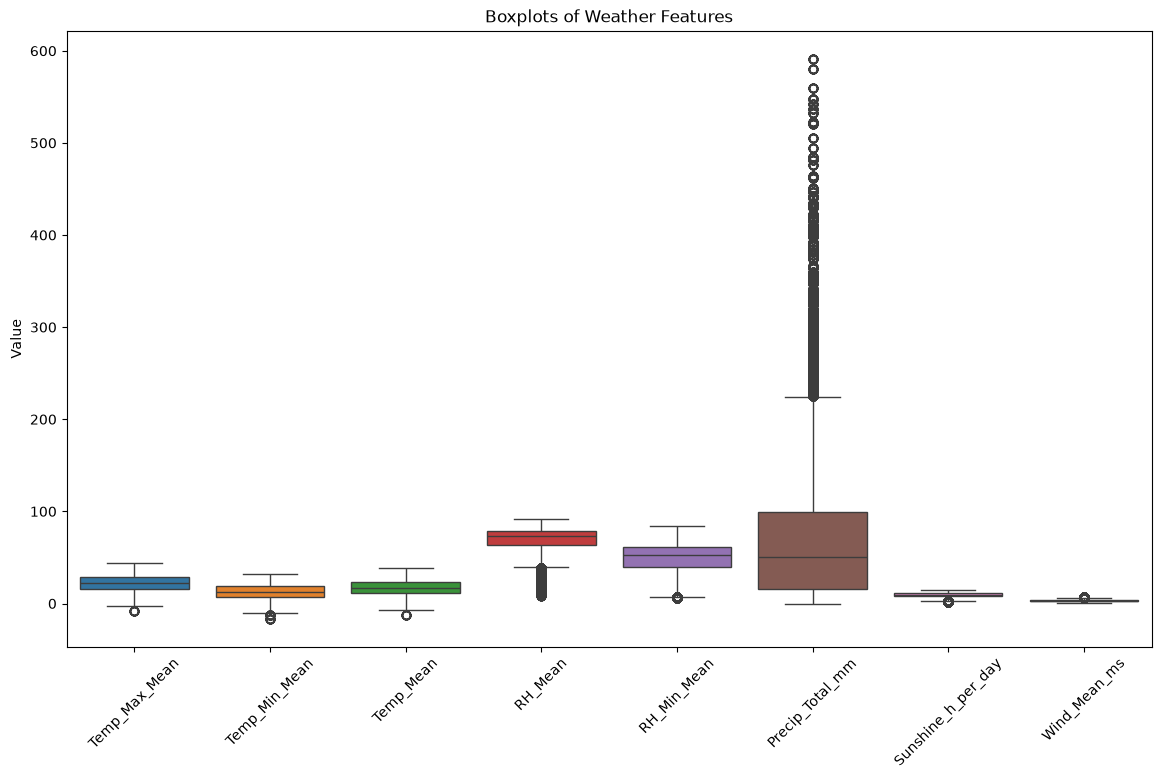

In [848]:
weather_cols = [
    "Temp_Max_Mean",
    "Temp_Min_Mean",
    "Temp_Mean",
    "RH_Mean",
    "RH_Min_Mean",
    "Precip_Total_mm",
    "Sunshine_h_per_day",
    "Wind_Mean_ms"
]

plt.figure(figsize=(14, 8))

sns.boxplot(data=df[weather_cols])

plt.xticks(rotation=45)
plt.title("Boxplots of Weather Features")
plt.ylabel("Value")

plt.show()

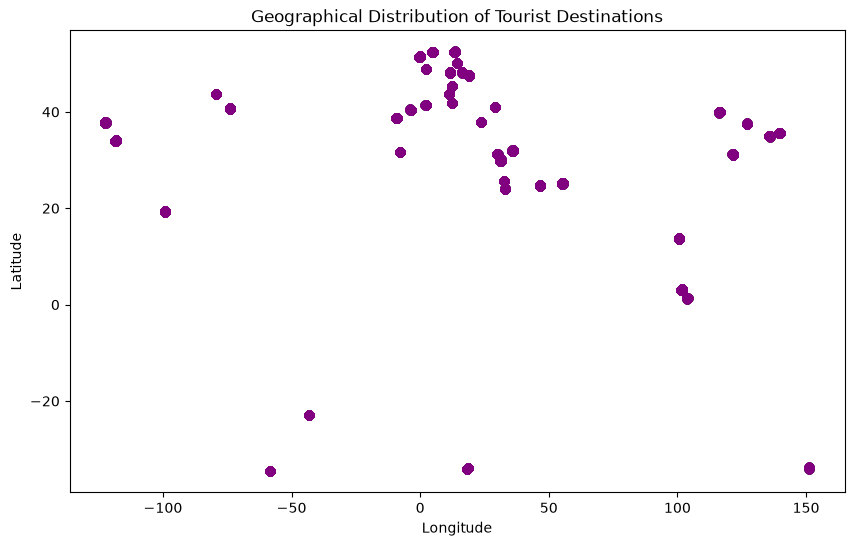

In [849]:
plt.figure(figsize=(10, 6))

plt.scatter(df["Longitude"],df["Latitude"],alpha=0.3 , color='purple')

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Distribution of Tourist Destinations")

plt.show()

In [850]:
cm = df.drop_duplicates(["City", "Year", "Month"]).copy()
cm["Hemisphere"] = cm["City_Center_Lat"].apply(lambda x: "South" if x < 0 else "North")
cm["month_sin"] = np.sin(2 * np.pi * cm["Month"] / 12).round(4)
cm["month_cos"] = np.cos(2 * np.pi * cm["Month"] / 12).round(4)
cm["is_south"] = (cm["City_Center_Lat"] < 0).astype(int)
print(cm.shape)

(5412, 35)


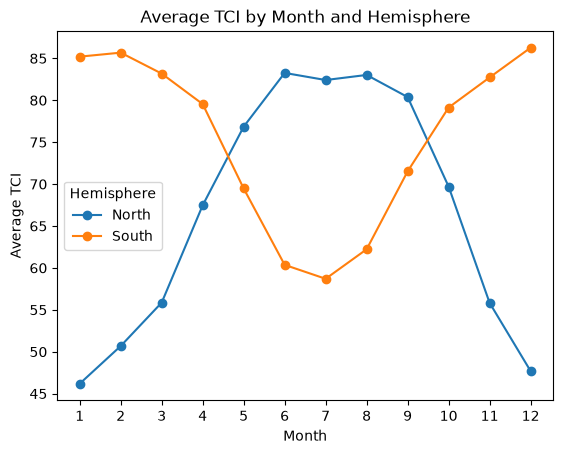

In [851]:
cm.groupby(["Month", "Hemisphere"])["TCI"].mean().unstack().plot(marker="o")
plt.xticks(range(1, 13))
plt.ylabel("Average TCI")
plt.title("Average TCI by Month and Hemisphere")
plt.show()

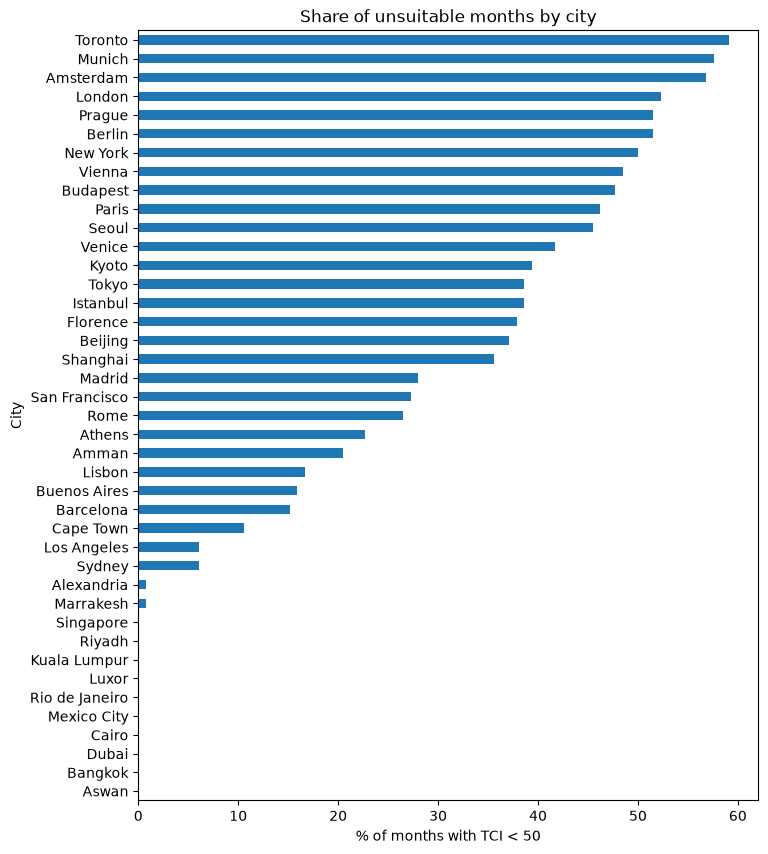

In [852]:
low = (cm.assign(low=cm["TCI"] < 50).groupby("City")["low"].mean() * 100).sort_values()
low.plot(kind="barh", figsize=(8, 10))
plt.xlabel("% of months with TCI < 50")
plt.title("Share of unsuitable months by city")
plt.show()

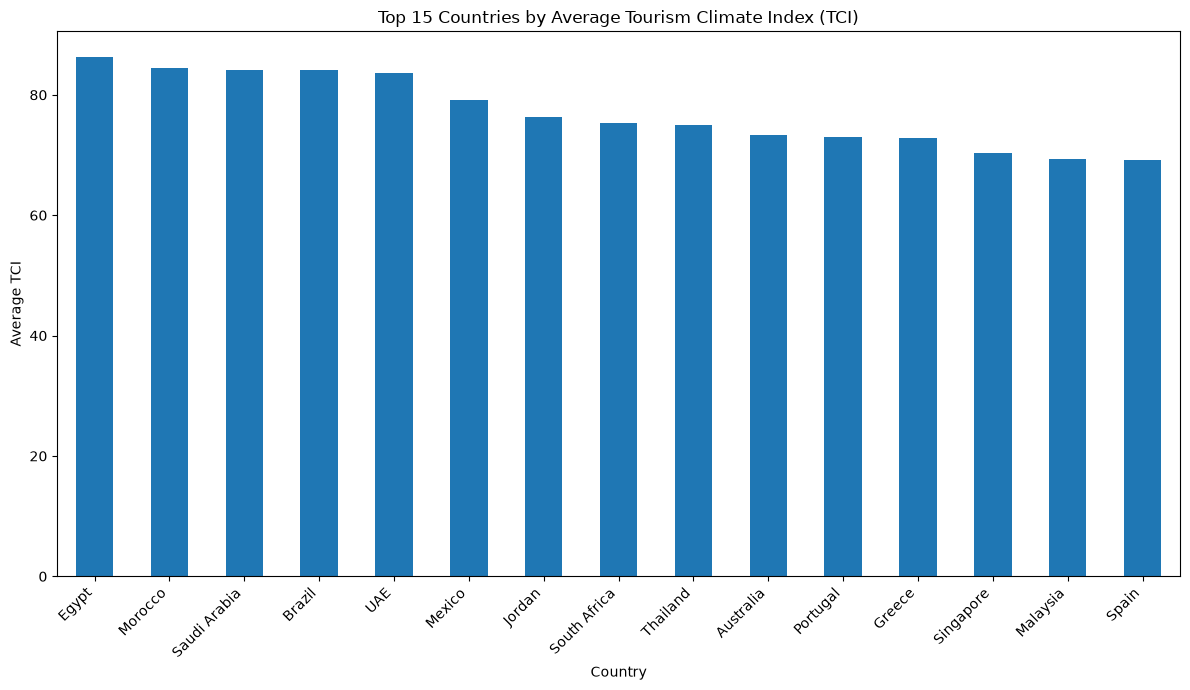

In [853]:
country_tci = (cm.groupby("Country_dest")["TCI"].mean().sort_values(ascending=False).head(15))

plt.figure(figsize=(12, 7))

country_tci.plot(kind="bar")

plt.xlabel("Country")
plt.ylabel("Average TCI")
plt.title("Top 15 Countries by Average Tourism Climate Index (TCI)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

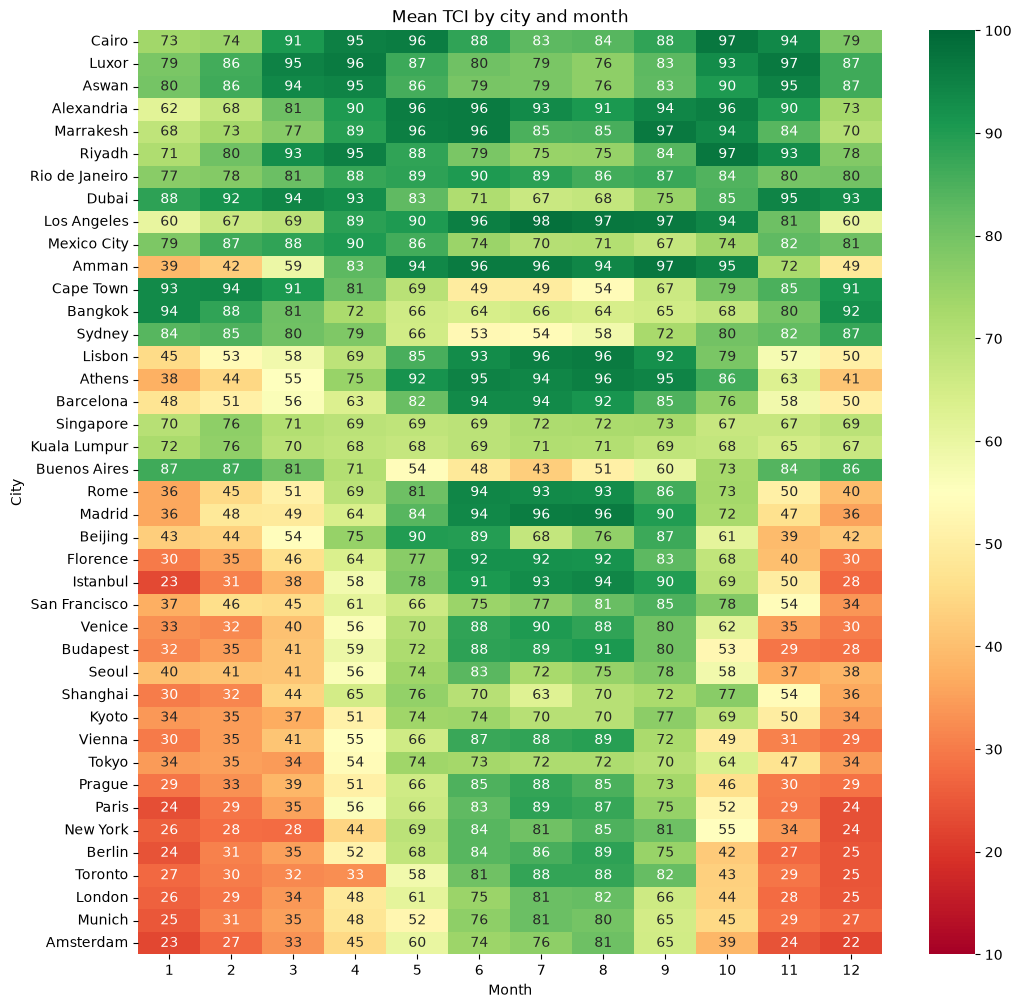

In [854]:
pivot = cm.groupby(["City", "Month"])["TCI"].mean().unstack()
pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]
plt.figure(figsize=(12, 12))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="RdYlGn", vmin=10, vmax=100)
plt.title("Mean TCI by city and month")
plt.show()

In [855]:
full = pd.read_csv('../cleaned_data/tourism_final_clean.csv')
places = full.drop_duplicates("Destination Name")
print("Number of places:", len(places))

Number of places: 978


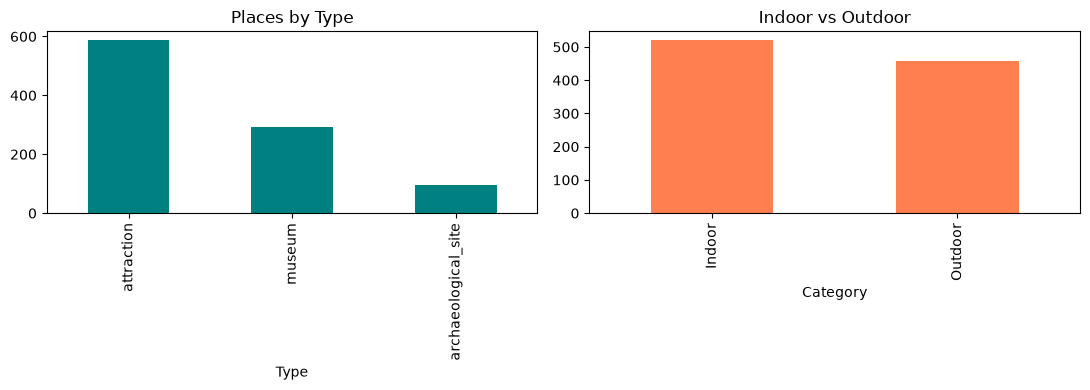

In [856]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
places["Type"].value_counts().plot(kind="bar", ax=ax[0], color="teal")
ax[0].set_title("Places by Type")
places["Category"].value_counts().plot(kind="bar", ax=ax[1], color="coral")
ax[1].set_title("Indoor vs Outdoor")
plt.tight_layout()
plt.show()

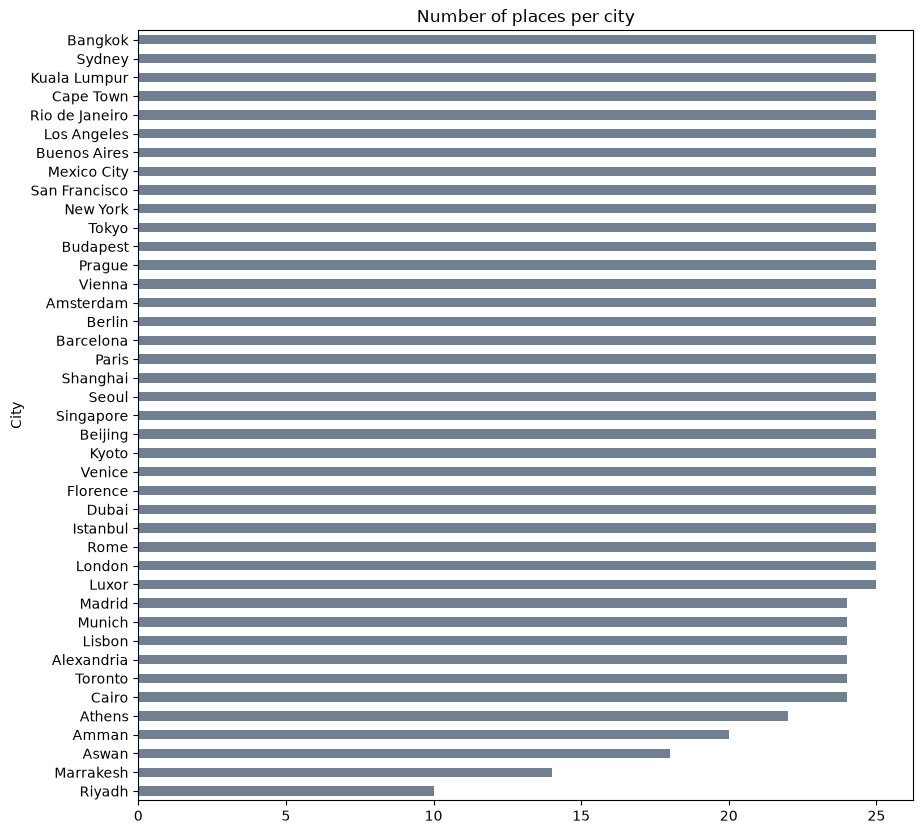

In [857]:
plt.figure(figsize=(10, 10))
places["City"].value_counts().sort_values().plot(kind="barh", color="slategray")
plt.title("Number of places per city")
plt.show()

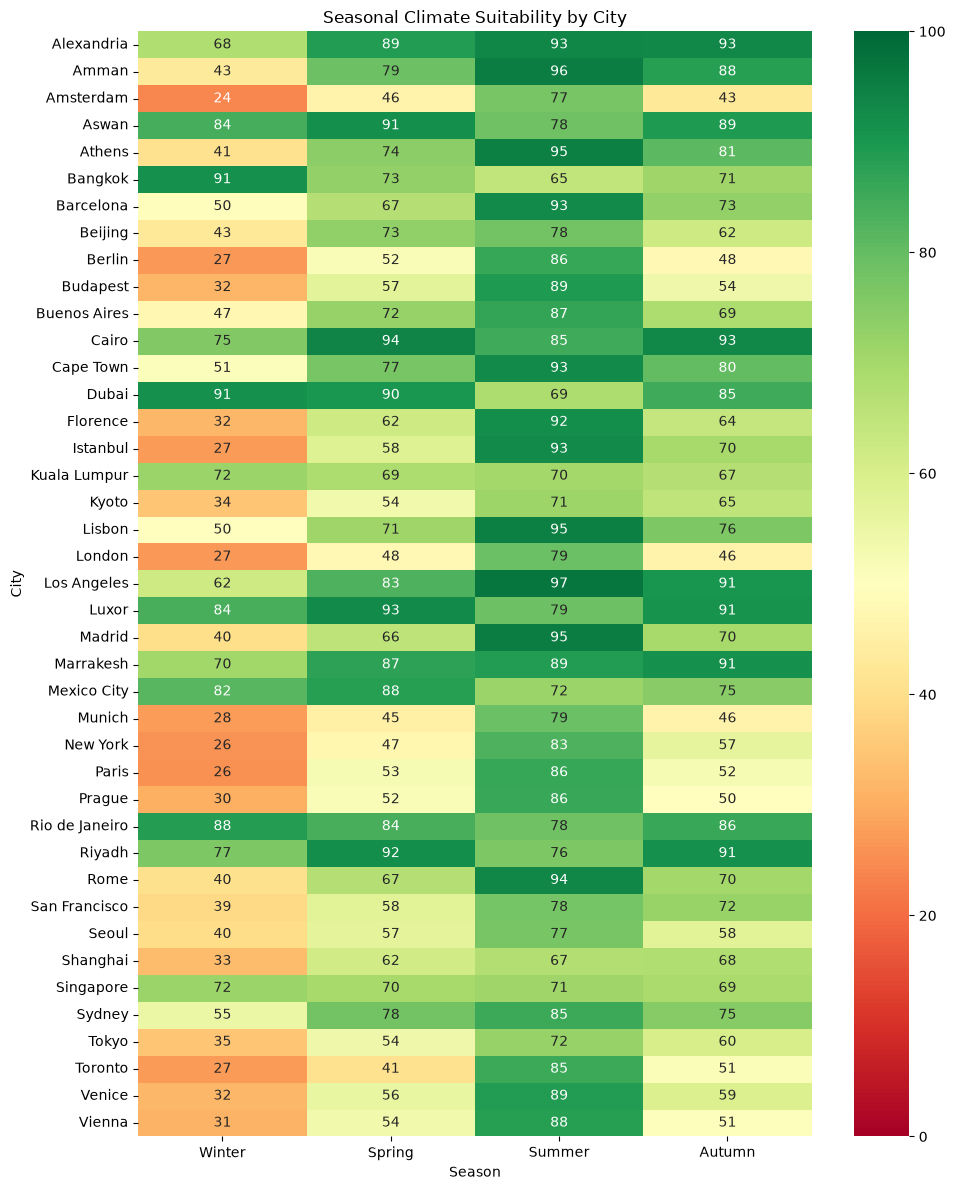

In [858]:
season_by_month = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

season_order = ["Winter", "Spring", "Summer", "Autumn"]

seasonal = cm.copy()
seasonal["Season"] = seasonal["Month"].map(season_by_month)

south = seasonal["Hemisphere"].eq("South")
seasonal.loc[south, "Season"] = seasonal.loc[south, "Season"].map({
    "Winter": "Summer", "Spring": "Autumn",
    "Summer": "Winter", "Autumn": "Spring"
})

seasonal_tci = seasonal.pivot_table(
    index="City", columns="Season", values="TCI", aggfunc="mean"
).reindex(columns=season_order)

plt.figure(figsize=(10, 12))
sns.heatmap(seasonal_tci, cmap="RdYlGn", vmin=0, vmax=100, annot=True, fmt=".0f")
plt.title("Seasonal Climate Suitability by City")
plt.xlabel("Season")
plt.ylabel("City")
plt.tight_layout()
plt.show()

In [859]:
drop_cols = ["Destination Name", "Type", "Category", "Latitude", "Longitude","Lat", "Lon", "Country_weather"]

In [860]:
df_2 = pd.read_csv("../cleaned_data/city_month_features.csv")

Best parameters: {'kneighborsregressor__n_neighbors': 7}
MAE:  2.87
RMSE: 3.86
R²:   0.970


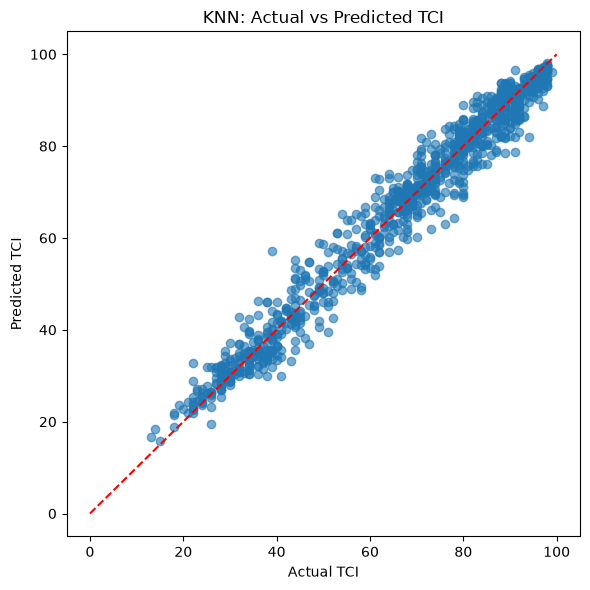

In [861]:


features = [
    "Temp_Max_Mean", "Temp_Min_Mean", "Temp_Mean",
    "RH_Mean", "RH_Min_Mean", "Precip_Total_mm",
    "Sunshine_h_per_day", "Wind_Mean_ms",
    "month_sin", "month_cos", "is_south"
]

# Keep available features and remove rows with missing values
features = [col for col in features if col in df_2.columns]
model_data = df_2[features + ["TCI"]].dropna()

X = model_data[features]
y = model_data["TCI"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

pipeline = make_pipeline(StandardScaler(), KNeighborsRegressor())

search = GridSearchCV(
    pipeline,
    param_grid={"kneighborsregressor__n_neighbors": [3, 5, 7, 9, 11, 15]},
    cv=5,
    scoring="neg_mean_absolute_error"
)
search.fit(X_train, y_train)

y_pred = search.predict(X_test)

print("Best parameters:", search.best_params_)
print(f"MAE:  {mean_absolute_error(y_test, y_pred):.2f}")
print(f"RMSE: {mean_squared_error(y_test, y_pred) ** 0.5:.2f}")
print(f"R²:   {r2_score(y_test, y_pred):.3f}")

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([0, 100], [0, 100], "r--")
plt.xlabel("Actual TCI")
plt.ylabel("Predicted TCI")
plt.title("KNN: Actual vs Predicted TCI")
plt.tight_layout()
plt.show()

In [862]:
cm = (
    df_2.groupby(["Month", "Country_dest"], as_index=False)["TCI"]
    .mean()
)

peak_country_by_month = (
    cm.sort_values(["Month", "TCI"], ascending=[True, False])
    .drop_duplicates("Month")
    .sort_values("Month")
    .reset_index(drop=True)
)

peak_country_by_month["Month_Name"] = peak_country_by_month["Month"].map({
    1: "January", 2: "February", 3: "March", 4: "April",
    5: "May", 6: "June", 7: "July", 8: "August",
    9: "September", 10: "October", 11: "November", 12: "December"
})

display(peak_country_by_month[["Month", "Month_Name", "Country_dest", "TCI"]])

,Month,Month_Name,Country_dest,TCI
0,1,January,Thailand,93.636364
1,2,February,South Africa,93.727273
2,3,March,UAE,94.363636
3,4,April,Saudi Arabia,95.272727
4,5,May,Morocco,95.545455
5,6,June,Morocco,96.363636
6,7,July,Jordan,96.181818
7,8,August,Portugal,96.181818
8,9,September,Jordan,97.181818
9,10,October,Saudi Arabia,97.090909


In [863]:

country_input = input("Enter the country name: ").strip()
location_input = input(
    "Enter a city or governorate (or press Enter to skip): "
).strip()

month_text = input("Enter the month (1-12): ").strip()

month_dict = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

try:
    month_input = int(month_text)
    if month_input not in month_dict:
        raise ValueError
except ValueError:
    print("Invalid month. Please enter a number from 1 to 12.")

else:
    country_col = (
        "Country" if "Country" in full.columns
        else "Country_dest" if "Country_dest" in full.columns
        else None
    )

    if country_col is None:
        print("Country column was not found.")
    else:
        matches = full[
            full[country_col].astype(str).str.strip().str.casefold()
            .eq(country_input.casefold())
            & pd.to_numeric(full["Month"], errors="coerce").eq(month_input)
        ].copy()

        # Filter by city/governorate only if the user entered one
        if location_input:
            location_cols = [
                col for col in ["City", "Governorate", "Province", "Region"]
                if col in matches.columns
            ]

            if not location_cols:
                print("No city/governorate column was found in the dataset.")
                matches = matches.iloc[0:0]
            else:
                location_mask = pd.Series(False, index=matches.index)

                for col in location_cols:
                    location_mask |= (
                        matches[col].astype("string")
                        .str.strip().str.casefold()
                        .eq(location_input.casefold())
                    )

                matches = matches[location_mask].copy()

        if matches.empty:
            print("No destinations found for these inputs.")
        else:
            matches["TCI"] = pd.to_numeric(
                matches["TCI"], errors="coerce"
            )
            matches = matches.dropna(subset=["TCI"])

            best = (
                matches.sort_values("TCI", ascending=False)
                .drop_duplicates(subset=["Destination Name"])
                .head(5)
                .reset_index(drop=True)
            )

            display(best)


,Destination Name,Type,Category,Latitude,Longitude,City,Country,Wikidata_ID,Sitelinks,Source,...,n_valid_days,n_days,CID,CIA,P_score,S_score,W_score,TCI,TCI_Category,Hemisphere
0,Malkata (Luxor),archaeological_site,Outdoor,25.71528,32.59111,Luxor,Egypt,Q431422,22.0,wikidata,...,28,28,5.0,3.0,5.0,5.0,3.5,93.0,Ideal,North
1,Dra' Abu el-Naga (Luxor),archaeological_site,Outdoor,25.73528,32.62056,Luxor,Egypt,Q676508,21.0,wikidata,...,29,29,5.0,3.0,5.0,5.0,3.5,93.0,Ideal,North
2,Medinet Habu (Luxor),archaeological_site,Outdoor,25.72000,32.60083,Luxor,Egypt,Q932622,27.0,wikidata,...,28,28,5.0,3.0,5.0,5.0,3.5,93.0,Ideal,North
3,Mortuary Temple of Seti I (Luxor),archaeological_site,Outdoor,25.73278,32.62806,Luxor,Egypt,Q375642,22.0,wikidata,...,28,28,5.0,3.0,5.0,5.0,3.5,93.0,Ideal,North
4,KV8 (Luxor),attraction,Outdoor,25.74083,32.60111,Luxor,Egypt,Q590096,27.0,wikidata,...,29,29,5.0,3.0,5.0,5.0,3.5,93.0,Ideal,North


In [864]:
''''
country_input = input("Enter the country name: ").strip()
month_text = input("Enter the month (1-12): ").strip()

month_dict = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

try:
    month_input = int(month_text)
    if month_input not in month_dict:
        raise ValueError

except ValueError:
    print("Invalid Month. Please enter a number from 1 to 12.")

else:
    # Support either Country or Country_dest
    country_col = (
        "Country" if "Country" in full.columns
        else "Country_dest" if "Country_dest" in full.columns
        else None
    )

    if country_col is None:
        raise ValueError("No country column found in full.")

    required_cols = ["Destination Name", "City", "TCI", "Month"]
    missing = [c for c in required_cols if c not in full.columns]

    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    matches = full[
        full[country_col].astype(str).str.strip().str.casefold()
        .eq(country_input.casefold())
        & pd.to_numeric(full["Month"], errors="coerce").eq(month_input)
    ].copy()

    if matches.empty:
        print(
            f"No data found for '{country_input}' "
            f"in {month_dict[month_input]}."
        )

    else:
        display_cols = [
            c for c in [
                "Destination Name", "City", "Type",
                "Category", "TCI", "TCI_Category"
            ]
            if c in matches.columns
        ]

        matches["TCI"] = pd.to_numeric(
            matches["TCI"], errors="coerce"
        )
        matches = matches.dropna(subset=["TCI"])

        best = (
            matches.sort_values("TCI", ascending=False)
            .drop_duplicates(subset=["Destination Name"])
            .head(5)[display_cols]
            .reset_index(drop=True)
        )

        print(
            f"Top 5 Destinations For {country_input.title()} "
            f"in {month_dict[month_input]}:"
        )
        
        display(best)'''


'\'\ncountry_input = input("Enter the country name: ").strip()\nmonth_text = input("Enter the month (1-12): ").strip()\n\nmonth_dict = {\n    1: "January", 2: "February", 3: "March",\n    4: "April", 5: "May", 6: "June",\n    7: "July", 8: "August", 9: "September",\n    10: "October", 11: "November", 12: "December"\n}\n\ntry:\n    month_input = int(month_text)\n    if month_input not in month_dict:\n        raise ValueError\n\nexcept ValueError:\n    print("Invalid Month. Please enter a number from 1 to 12.")\n\nelse:\n    # Support either Country or Country_dest\n    country_col = (\n        "Country" if "Country" in full.columns\n        else "Country_dest" if "Country_dest" in full.columns\n        else None\n    )\n\n    if country_col is None:\n        raise ValueError("No country column found in full.")\n\n    required_cols = ["Destination Name", "City", "TCI", "Month"]\n    missing = [c for c in required_cols if c not in full.columns]\n\n    if missing:\n        raise ValueError

## Final project workflow: country-specific DBSCAN, recommendations, and interactive map



In [865]:
from pathlib import Path
import html
import folium
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN

OUTPUT_DIR = Path("processed_data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Use unique destination-coordinate records from df, which contains TCI and coordinates.
required_place_cols = [
    "Destination Name", "City", "Country_dest", "Latitude", "Longitude"
]
missing = [c for c in required_place_cols if c not in df.columns]
if missing:
    raise ValueError(f"Attraction data is missing columns: {missing}")

optional_place_cols = [c for c in ["Type", "Category", "TCI", "TCI_Category"] if c in df.columns]
places_base = df[required_place_cols + optional_place_cols].copy()

places_base["Latitude"] = pd.to_numeric(places_base["Latitude"], errors="coerce")
places_base["Longitude"] = pd.to_numeric(places_base["Longitude"], errors="coerce")
places_base["Country_dest"] = places_base["Country_dest"].astype("string").str.strip()

valid_coords_mask = (
    places_base["Latitude"].between(-90, 90)
    & places_base["Longitude"].between(-180, 180)
    & places_base["Country_dest"].notna()
    & places_base["Destination Name"].notna()
)
invalid_places = places_base.loc[~valid_coords_mask].copy()
places_valid = places_base.loc[valid_coords_mask].drop_duplicates(
    subset=["Country_dest", "Destination Name", "Latitude", "Longitude"]
).copy()

print("Unique attractions with valid coordinates:", len(places_valid))
print("Records excluded due to missing/invalid coordinates:", len(invalid_places))

# DBSCAN parameters: 5 km neighborhood, minimum 3 unique coordinate points.
EARTH_RADIUS_KM = 6371.0088
EPS_KM = 5
MIN_SAMPLES = 3
eps_radians = EPS_KM / EARTH_RADIUS_KM

# Cluster unique coordinates within each country separately.
coordinate_rows = places_valid[
    ["Country_dest", "Latitude", "Longitude"]
].drop_duplicates().copy()
coordinate_rows["spatial_cluster"] = -1

for country, group in coordinate_rows.groupby("Country_dest", dropna=True):
    coords_radians = np.radians(group[["Latitude", "Longitude"]].to_numpy())
    model = DBSCAN(
        eps=eps_radians,
        min_samples=MIN_SAMPLES,
        metric="haversine",
        algorithm="ball_tree"
    )
    coordinate_rows.loc[group.index, "spatial_cluster"] = model.fit_predict(coords_radians)

places_with_clusters = places_valid.merge(
    coordinate_rows,
    on=["Country_dest", "Latitude", "Longitude"],
    how="left",
    validate="many_to_one"
)
places_with_clusters["spatial_cluster"] = (
    places_with_clusters["spatial_cluster"].fillna(-1).astype(int)
)

cluster_summary = (
    places_with_clusters.groupby(["Country_dest", "spatial_cluster"])
    .agg(
        Attractions=("Destination Name", "nunique"),
        Cities=("City", "nunique")
    )
    .reset_index()
    .sort_values(["Country_dest", "spatial_cluster"])
)
country_cluster_summary = (
    coordinate_rows.groupby("Country_dest")
    .agg(
        Unique_Coordinate_Groups=("spatial_cluster", "size"),
        Cluster_Count=("spatial_cluster", lambda s: s[s >= 0].nunique()),
        Noise_Coordinates=("spatial_cluster", lambda s: (s == -1).sum())
    )
    .reset_index()
)



Unique attractions with valid coordinates: 987
Records excluded due to missing/invalid coordinates: 0


In [866]:



OUTPUT_DIR = Path("processed_data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Full attraction dataset with cluster labels
places_with_clusters.to_csv(
    OUTPUT_DIR / "attractions_with_clusters.csv",
    index=False,
    encoding="utf-8-sig"
)

# 2. Summary for each country and cluster
cluster_summary.to_csv(
    OUTPUT_DIR / "cluster_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

# 3. Summary for each country
country_cluster_summary.to_csv(
    OUTPUT_DIR / "country_cluster_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Cluster data files saved successfully:")
for file_path in sorted(OUTPUT_DIR.glob("*cluster*.csv")):
    print(f"{file_path} | {file_path.stat().st_size:,} bytes")


Cluster data files saved successfully:
processed_data\attractions_with_clusters.csv | 100,484 bytes
processed_data\cluster_summary.csv | 1,205 bytes
processed_data\country_cluster_summary.csv | 552 bytes


In [867]:

# Interactive Folium map for a selected country and month.
# Red = Top 5 recommendations; blue = other attractions;
# gray = DBSCAN noise.

TOP5_COLOR = "#e6194b"
OTHER_COLOR = "#4363d8"
NOISE_COLOR = "#808080"


def make_country_map(
    country, month, recommendations, show_all_attractions=True):
    country = str(country).strip()

    country_places = places_with_clusters[
        places_with_clusters["Country_dest"]
        .astype("string")
        .str.strip()
        .str.casefold()
        .eq(country.casefold())
    ].copy()

    if country_places.empty:
        raise ValueError(
            f"No mapped attractions found for {country!r}."
        )

    # Ensure coordinates are valid
    for col in ["Latitude", "Longitude"]:
        country_places[col] = pd.to_numeric(
            country_places[col], errors="coerce"
        )

    country_places = country_places.dropna(
        subset=["Latitude", "Longitude"]
    )

    if country_places.empty:
        raise ValueError(
            f"No valid coordinates found for {country!r}."
        )

    if "spatial_cluster" not in country_places.columns:
        raise ValueError("The spatial_cluster column is missing.")

    top = recommendations.copy()

    if "Destination Name" not in top.columns:
        raise ValueError(
            "Recommendation results must contain Destination Name."
        )

    top_names = set(
        top["Destination Name"]
        .dropna()
        .astype(str)
        .str.strip()
        .str.casefold()
    )

    center = [
        country_places["Latitude"].mean(),
        country_places["Longitude"].mean()
    ]

    map_obj = folium.Map(
    location=center,
    zoom_start=5,
    tiles="OpenStreetMap",
    width="100%",
    height=650,
    control_scale=True
)

    if show_all_attractions:
        for _, row in country_places.iterrows():
            cluster_id = int(row["spatial_cluster"])
            destination = str(row["Destination Name"]).strip()
            is_top = destination.casefold() in top_names

            if is_top:
                color = TOP5_COLOR
            elif cluster_id == -1:
                color = NOISE_COLOR
            else:
                color = OTHER_COLOR

            city = html.escape(str(row.get("City", "")))
            destination_safe = html.escape(destination)
            country_safe = html.escape(
                str(row["Country_dest"])
            )

            popup = (
                f"<b>{destination_safe}</b><br>"
                f"City: {city}<br>"
                f"Country: {country_safe}<br>"
                f"DBSCAN cluster: {cluster_id}<br>"
                f"Top 5 recommendation: "
                f"{'Yes' if is_top else 'No'}"
            )

            folium.CircleMarker(
                location=[
                    row["Latitude"],
                    row["Longitude"]
                ],
                radius=7 if is_top else 4,
                color=color,
                fill=True,
                fill_color=color,
                fill_opacity=0.85,
                weight=2 if is_top else 1,
                popup=folium.Popup(popup, max_width=320),
                tooltip=destination
            ).add_to(map_obj)

    # Fit the map to the available attraction coordinates
    bounds = [
        [
            country_places["Latitude"].min(),
            country_places["Longitude"].min()
        ],
        [
            country_places["Latitude"].max(),
            country_places["Longitude"].max()
        ]
    ]
    map_obj.fit_bounds(bounds, padding=(20, 20))

    # Add a clear legend
    legend_html = """
    <div style="
        position: fixed;
        bottom: 25px;
        left: 25px;
        z-index: 9999;
        background: white;
        padding: 12px 15px;
        border: 1px solid #bbb;
        border-radius: 8px;
        font-size: 13px;
        line-height: 1.7;
        box-shadow: 0 2px 6px rgba(0,0,0,0.2);
    ">
        <b>Map Legend</b><br>
        <span style="color:#e6194b;">●</span>
        Top 5 recommendations<br>
        <span style="color:#4363d8;">●</span>
        Other clustered attractions<br>
        <span style="color:#808080;">●</span>
        Noise (not assigned to a cluster)
    </div>
    """

    map_obj.get_root().html.add_child(
        folium.Element(legend_html)
    )

    return map_obj, top


# Use the country and month selected in the earlier notebook cell
map_country = (
    country_input
    if "country_input" in globals() and country_input
    else input("Enter country for map: ").strip()
)

map_month = (
    month_input
    if "month_input" in globals()
    and isinstance(month_input, int)
    and month_input in range(1, 13)
    else int(input("Enter month for map (1-12): ").strip())
)

try:
    country_map, map_top5 = make_country_map(
    map_country,
    map_month,
    recommendations=best
)

    display(map_top5)
    display(country_map)

    output_dir = Path(OUTPUT_DIR)
    output_dir.mkdir(parents=True, exist_ok=True)

    output_file = output_dir / "selected_country_map.html"
    country_map.save(str(output_file))

    print(f"Map saved to: {output_file.resolve()}")

except (ValueError, KeyError) as exc:
    print(f"Could not create map: {exc}")


,Destination Name,Type,Category,Latitude,Longitude,City,Country,Wikidata_ID,Sitelinks,Source,...,n_valid_days,n_days,CID,CIA,P_score,S_score,W_score,TCI,TCI_Category,Hemisphere
0,Malkata (Luxor),archaeological_site,Outdoor,25.71528,32.59111,Luxor,Egypt,Q431422,22.0,wikidata,...,28,28,5.0,3.0,5.0,5.0,3.5,93.0,Ideal,North
1,Dra' Abu el-Naga (Luxor),archaeological_site,Outdoor,25.73528,32.62056,Luxor,Egypt,Q676508,21.0,wikidata,...,29,29,5.0,3.0,5.0,5.0,3.5,93.0,Ideal,North
2,Medinet Habu (Luxor),archaeological_site,Outdoor,25.72000,32.60083,Luxor,Egypt,Q932622,27.0,wikidata,...,28,28,5.0,3.0,5.0,5.0,3.5,93.0,Ideal,North
3,Mortuary Temple of Seti I (Luxor),archaeological_site,Outdoor,25.73278,32.62806,Luxor,Egypt,Q375642,22.0,wikidata,...,28,28,5.0,3.0,5.0,5.0,3.5,93.0,Ideal,North
4,KV8 (Luxor),attraction,Outdoor,25.74083,32.60111,Luxor,Egypt,Q590096,27.0,wikidata,...,29,29,5.0,3.0,5.0,5.0,3.5,93.0,Ideal,North


Map saved to: C:\Users\Administrator\Desktop\Boss_level\final_project_data\python files\processed_data\selected_country_map.html


In [869]:
full.to_csv("../tourism_streamlit_app/full.csv", index=False)
places_with_clusters.to_csv("../tourism_streamlit_app/places_with_clusters.csv", index=False)